In [34]:
from sklearn.datasets import fetch_olivetti_faces

data=fetch_olivetti_faces()

X = data.data
y = data.target

print(X.shape)
print(y.shape)

(400, 4096)
(400,)


In [35]:
print(data)

{'data': array([[0.30991736, 0.3677686 , 0.41735536, ..., 0.15289256, 0.16115703,
        0.1570248 ],
       [0.45454547, 0.47107437, 0.5123967 , ..., 0.15289256, 0.15289256,
        0.15289256],
       [0.3181818 , 0.40082645, 0.49173555, ..., 0.14049587, 0.14876033,
        0.15289256],
       ...,
       [0.5       , 0.53305787, 0.607438  , ..., 0.17768595, 0.14876033,
        0.19008264],
       [0.21487603, 0.21900827, 0.21900827, ..., 0.57438016, 0.59090906,
        0.60330576],
       [0.5165289 , 0.46280992, 0.28099173, ..., 0.35950413, 0.3553719 ,
        0.38429752]], dtype=float32), 'images': array([[[0.30991736, 0.3677686 , 0.41735536, ..., 0.37190083,
         0.3305785 , 0.30578512],
        [0.3429752 , 0.40495867, 0.43801653, ..., 0.37190083,
         0.338843  , 0.3140496 ],
        [0.3429752 , 0.41735536, 0.45041323, ..., 0.38016528,
         0.338843  , 0.29752067],
        ...,
        [0.21487603, 0.20661157, 0.2231405 , ..., 0.15289256,
         0.16528925, 0.17

In [36]:
import numpy as np
#Roll Number- M26CSA005
roll_num_char=26005
seed=roll_num_char 
rng=np.random.default_rng(seed)

print(seed)

26005


In [37]:
Xtrain_ids=[]
Xval_ids=[]
Xtest_ids=[]

for face in range(40):
    ids=np.where(y == face)[0]
    rng.shuffle(ids)

    Xtrain_ids.extend(ids[:6])
    Xval_ids.extend(ids[6:8])
    Xtest_ids.extend(ids[8:])

Xtrain_ids=np.array(Xtrain_ids)
Xval_ids=np.array(Xval_ids)
Xtest_ids=np.array(Xtest_ids)


np.savez(
    "olivetti_split.npz",
    Xtrain_ids=Xtrain_ids,
    Xval_ids=Xval_ids,
    Xtest_ids=Xtest_ids
)


X_train, y_train = X[Xtrain_ids], y[Xtrain_ids]
X_val, y_val = X[Xval_ids], y[Xval_ids]
X_test, y_test = X[Xtest_ids], y[Xtest_ids]


In [38]:
import matplotlib.pyplot as plt

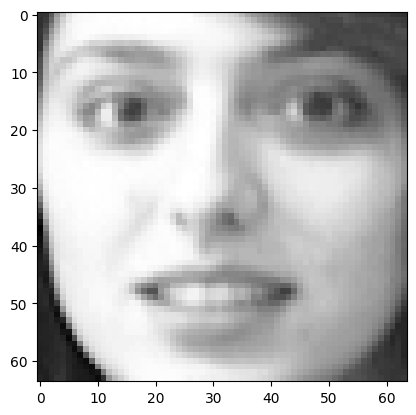

In [39]:
plt.imshow(X_test[14].reshape(64, 64), cmap="gray")
plt.show()

In [40]:
Xtest_mask=X_test.copy()
Xtest_mask=Xtest_mask.reshape(-1,64,64)
Xtest_mask[:,24:40,24:40]=0
Xtest_mask=Xtest_mask.reshape(-1,4096)

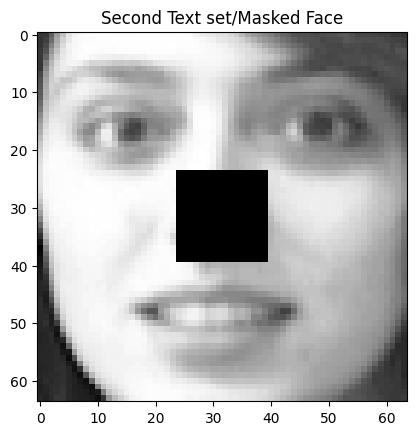

In [41]:
plt.imshow(Xtest_mask[14].reshape(64, 64), cmap="gray")
plt.title("Second Text set/Masked Face")
plt.show()

# Q1. Decision tree baseline and bagging from scratch

In [42]:
#(a) First establish a single tree baseline. Train DecisionTreeClassifier models with max depth∈ {2, 4, 8, 16, None}
#and min samples leaf∈ {1, 2, 4}. Select one setting using validation accuracy only and freeze it. Report train,
#validation and test accuracy, number of leaves, mean samples per leaf and the fraction of leaves containing only
#one training example. Explain what changes as depth increases.

In [43]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [44]:
depths=[2,8,4,16,None]
leaf_sizes=[1,2,4]

frozen_results=[]

for depth in depths:
    for leaf_size in leaf_sizes:

        tree=DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=leaf_size,
            random_state=seed
        )


        tree.fit(X_train,y_train)

        train_pred=tree.predict(X_train)
        val_pred=tree.predict(X_val)

        train_acc=accuracy_score(y_train,train_pred)
        val_acc=accuracy_score(y_val,val_pred)

        frozen_results.append({
            "depth":depth,
            "leaf_size":leaf_size,
            "train_acc":train_acc,
            "val_acc":val_acc,
            "tree":tree
        })

        if len(frozen_results) == 1:
            print(f"{'Depth':<8}{'Leaf Size':<12}{'Train Accuracy':<18}{'Validation Accuracy'}")
        print(
            f"{str(depth):<8}"
            f"{leaf_size:<12}"
            f"{train_acc:<18.4f}"
            f"{val_acc:.4f}"
        )

Depth   Leaf Size   Train Accuracy    Validation Accuracy
2       1           0.0750            0.0625
2       2           0.0750            0.0625
2       4           0.0750            0.0625
8       1           0.2250            0.1875
8       2           0.2250            0.1875
8       4           0.2250            0.1875
4       1           0.1250            0.1125
4       2           0.1250            0.1125
4       4           0.1250            0.1125
16      1           0.4250            0.2750
16      2           0.4250            0.2750
16      4           0.4250            0.2750
None    1           1.0000            0.6125
None    2           0.9875            0.5875
None    4           0.9792            0.5750


In [45]:
best = max(frozen_results, key=lambda item: item["val_acc"])

tree = best["tree"]
print("Depth:", best["depth"])
print("Minimum leaf size:", best["leaf_size"])
print("Training accuracy:", round(best["train_acc"], 4))
print("Validation accuracy:", round(best["val_acc"], 4))


Depth: None
Minimum leaf size: 1
Training accuracy: 1.0
Validation accuracy: 0.6125


In [46]:
test_pred = tree.predict(X_test)
test_acc = accuracy_score(y_test, test_pred)

leaf_ids = tree.apply(X_train)

leaf_numbers, leaf_counts = np.unique(
    leaf_ids, return_counts=True
)

num_leaves = len(leaf_counts)
mean_samples = np.mean(leaf_counts)
single_sample_fraction = np.mean(leaf_counts == 1)

print("Results/solution")
print("\nDepth:", best["depth"])
print("Minimum leaf size:", best["leaf_size"])
print("Training accuracy:", round(best["train_acc"], 4))
print("Validation accuracy:", round(best["val_acc"], 4))
print("Test accuracy:", round(test_acc, 4))
print("Number of leaves:", num_leaves)
print("Mean samples per leaf:", round(mean_samples, 2))
print(
    "Fraction of leaves with one training image:",
    round(single_sample_fraction, 4)
)


Q1 (a) results/solution

Depth: None
Minimum leaf size: 1
Training accuracy: 1.0
Validation accuracy: 0.6125
Test accuracy: 0.4625
Number of leaves: 46
Mean samples per leaf: 5.22
Fraction of leaves with one training image: 0.1304


# (b) Implement bagging yourself using bootstrap samples of the original training set size and the frozen tree setting from part (a). Use B ∈ {1, 5, 10, 25, 50, 100, 200}. For every B, report train, validation and test accuracy and the average number of distinct examples in one bootstrap sample. Compare the last quantity with its theoretical expectation.

In [47]:
tree_counts = [1, 5, 10, 25, 50, 100, 200]
bagg_rng=np.random.default_rng(seed)

trees=[]
samples=[]
bagg_results=[]

for i in range(200):
    ids=bagg_rng.integers(0,len(X_train),size=len(X_train))
    new_tree=DecisionTreeClassifier(
        max_depth=None,
        min_samples_leaf=1,
        random_state=seed+1
    )

    new_tree.fit(X_train[ids],y_train[ids])
    trees.append(new_tree)
    samples.append(ids)

    if i+1 in tree_counts:
        models=trees[:i+1]
        
        train_votes=np.array([
            model.predict(X_train) for model in models
        ])
        val_votes=np.array([
            model.predict(X_val) for model in models
        ])
        test_votes=np.array([
            model.predict(X_test) for model in models
        ])

        train_pred=np.array([
            np.bincount(train_votes[:,j],minlength=40).argmax()
            for j in range(len(X_train))
        ])

        val_pred=np.array([
            np.bincount(val_votes[:,j],minlength=40).argmax()
            for j in range(len(X_val))
        ])

        test_pred=np.array([
             np.bincount(test_votes[:,j],minlength=40).argmax()
             for j in range(len(X_test))
        ])

        distinct=np.mean([
            len(np.unique(sample)) for sample in samples
        ])

        bagg_results.append({
            "B":i+1,
            "train_acc": accuracy_score(y_train, train_pred),
            "val_acc": accuracy_score(y_val, val_pred),
            "test_acc": accuracy_score(y_test, test_pred),
            "distinct": distinct
        })


In [48]:
print(
    f"{'B':<8}{'Train Accuracy':<18}"
    f"{'Validation Accuracy':<22}"
    f"{'Test Accuracy':<18}{'Distinct Images'}"
)

for result in bagg_results:
    print(
        f"{result['B']:<8}"
        f"{result['train_acc']:<18.4f}"
        f"{result['val_acc']:<22.4f}"
        f"{result['test_acc']:<18.4f}"
        f"{result['distinct']:.2f}"
    )


B       Train Accuracy    Validation Accuracy   Test Accuracy     Distinct Images
1       0.7208            0.4000                0.3875            149.00
5       0.9750            0.6000                0.6750            152.20
10      0.9958            0.7250                0.7875            151.50
25      1.0000            0.8500                0.8875            152.24
50      1.0000            0.8750                0.9125            152.74
100     1.0000            0.9125                0.9125            152.43
200     1.0000            0.9125                0.8875            152.70


In [49]:

n = len(X_train)

expected = n * (1 - (1 - 1/n) ** n)

print("\nTheoretical Expected distinct images:", round(expected, 2))
print("\nComparison with observed values:")


print(
    f"{'B':<8}{'Observed':<12}"
    f"{'Expected':<22}"
   
)

for result in bagg_results:
    print(
        f"{result['B']:<8}"
        f"{result['distinct']:<12.2f}"
        f"{expected:.4f}"
        
     )


Theoretical Expected distinct images: 151.89

Comparison with observed values:
B       Observed    Expected              
1       149.00      151.8932
5       152.20      151.8932
10      151.50      151.8932
25      152.24      151.8932
50      152.74      151.8932
100     152.43      151.8932
200     152.70      151.8932


Graph


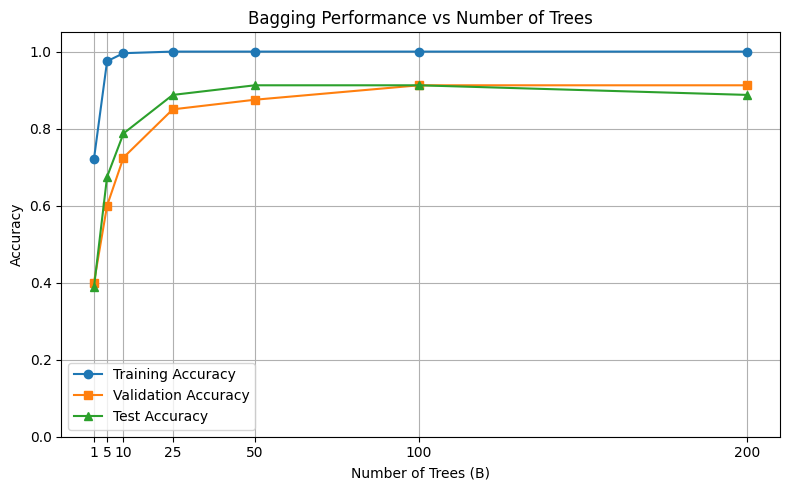

In [50]:
print("Graph")
B = [result["B"] for result in bagg_results]
train_acc = [result["train_acc"] for result in bagg_results]
val_acc = [result["val_acc"] for result in bagg_results]
test_acc = [result["test_acc"] for result in bagg_results]

plt.figure(figsize=(8, 5))

plt.plot(B, train_acc, marker="o", label="Training Accuracy")
plt.plot(B, val_acc, marker="s", label="Validation Accuracy")
plt.plot(B, test_acc, marker="^", label="Test Accuracy")

plt.xlabel("Number of Trees (B)")
plt.ylabel("Accuracy")
plt.title("Bagging Performance vs Number of Trees")

plt.xticks(B)
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# (c) For every B, compute out of bag accuracy, average pairwise disagreement between trees, and mean vote margin, where vote margin is the winning vote fraction minus the runner up vote fraction. Plot all three against B. Select one final ensemble size using the validation set and explain whether out of bag accuracy, disagreement and vote margin tell the same story.

In [51]:
oob_results = []
disagreement_results = []
margin_results = []

for B in tree_counts:
    models = trees[:B]
    bootstrap_samples = samples[:B]

    oob_votes = [[] for _ in range(len(X_train))]
    for i in range(B):
        used = np.zeros(len(X_train), dtype=bool)
        used[bootstrap_samples[i]] = True

        oob_ids = np.where(~used)[0]

        if len(oob_ids) > 0:
            predictions = models[i].predict(X_train[oob_ids])

            for j, prediction in zip(oob_ids, predictions):
                oob_votes[j].append(prediction)

    correct = 0
    checked = 0

    for j in range(len(X_train)):
        if len(oob_votes[j]) > 0:
            prediction = np.bincount(
                oob_votes[j], minlength=40
            ).argmax()

            if prediction == y_train[j]:
                correct += 1

            checked += 1

    oob_acc = correct / checked if checked > 0 else np.nan
    oob_results.append(oob_acc)
    
    val_votes = np.array([
        model.predict(X_val) for model in models
    ])

    pairwise_scores = []

    for i in range(B):
        for j in range(i + 1, B):
            disagreement = np.mean(val_votes[i] != val_votes[j])
            pairwise_scores.append(disagreement)

    if len(pairwise_scores) > 0:
        mean_disagreement = np.mean(pairwise_scores)
    else:
        mean_disagreement = np.nan

    disagreement_results.append(mean_disagreement)

    vote_margins = []

    for j in range(len(X_val)):
        counts = np.bincount(val_votes[:, j], minlength=40)
        counts = np.sort(counts)[::-1]

        margin = (counts[0] - counts[1]) / B
        vote_margins.append(margin)

    mean_margin = np.mean(vote_margins)
    margin_results.append(mean_margin)

In [52]:
print(
    f"{'B':<8}"
    f"{'OOB Accuracy':<18}"
    f"{'Disagreement':<18}"
    f"{'Mean Vote Margin'}"
)

for i in range(len(tree_counts)):
    disagreement_text = (
        f"{disagreement_results[i]:.4f}"
        if not np.isnan(disagreement_results[i])
        else "N/A"
    )

    print(
        f"{tree_counts[i]:<8}"
        f"{oob_results[i]:<18.4f}"
        f"{disagreement_text:<18}"
        f"{margin_results[i]:.4f}"
    )


B       OOB Accuracy      Disagreement      Mean Vote Margin
1       0.2637            N/A               1.0000
5       0.3641            0.7250            0.2825
10      0.4008            0.7281            0.3112
25      0.5958            0.7477            0.3045
50      0.6708            0.7543            0.3065
100     0.7292            0.7633            0.3078
200     0.7792            0.7580            0.3163


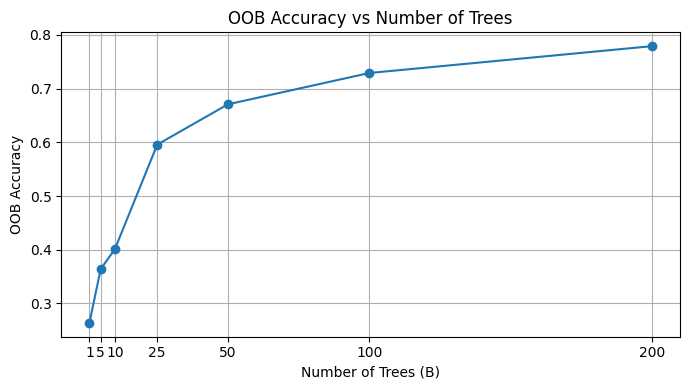

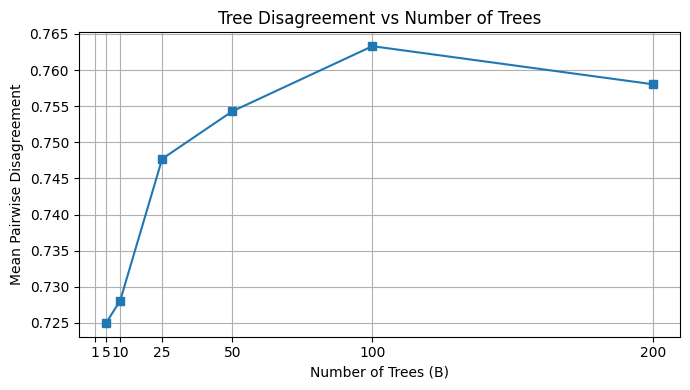

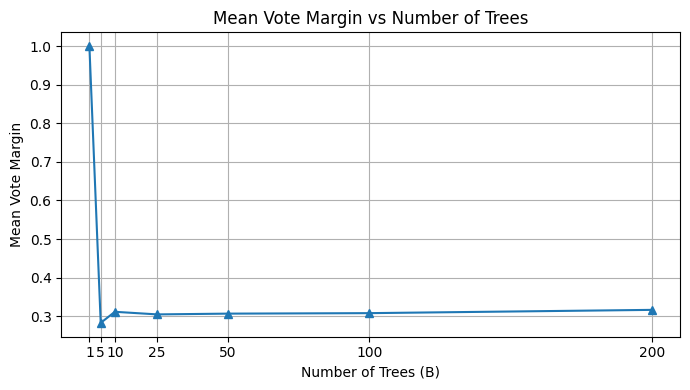

In [53]:
plt.figure(figsize=(7, 4))
plt.plot(tree_counts, oob_results, marker="o")
plt.xlabel("Number of Trees (B)")
plt.ylabel("OOB Accuracy")
plt.title("OOB Accuracy vs Number of Trees")
plt.xticks(tree_counts)
plt.grid(True)
plt.tight_layout()
plt.show()


plt.figure(figsize=(7, 4))
plt.plot(tree_counts, disagreement_results, marker="s")
plt.xlabel("Number of Trees (B)")
plt.ylabel("Mean Pairwise Disagreement")
plt.title("Tree Disagreement vs Number of Trees")
plt.xticks(tree_counts)
plt.grid(True)
plt.tight_layout()
plt.show()


plt.figure(figsize=(7, 4))
plt.plot(tree_counts, margin_results, marker="^")
plt.xlabel("Number of Trees (B)")
plt.ylabel("Mean Vote Margin")
plt.title("Mean Vote Margin vs Number of Trees")
plt.xticks(tree_counts)
plt.grid(True)
plt.tight_layout()
plt.show()

# (d) Compare the frozen single tree and the final bagged model on both the clean and masked test sets. Report accuracy and prediction confidence for both. Find two faces where bagging corrects the tree and two where both are wrong. Show the tree prediction and bagging vote counts, and use these cases to explain what type of error bagging can reduce and what type it cannot.

In [54]:
single_tree = best["tree"]
final_B = 100
final_trees = trees[:final_B]
test_sets = {
    "Clean": X_test,
    "Masked": Xtest_mask
}

print(
    f"{'Test Set':<12}"
    f"{'Model':<18}"
    f"{'Accuracy':<15}"
    f"{'Mean Confidence'}"
)

for set_name, X_current in test_sets.items():
    tree_pred = single_tree.predict(X_current)
    tree_prob = single_tree.predict_proba(X_current)
    tree_conf = np.max(tree_prob, axis=1)

    tree_acc = accuracy_score(y_test, tree_pred)
    mean_tree_conf = np.mean(tree_conf)

    print(
        f"{set_name:<12}"
        f"{'Single Tree':<18}"
        f"{tree_acc:<15.4f}"
        f"{mean_tree_conf:.4f}"
    )

    bag_votes = np.array([
        model.predict(X_current) for model in final_trees
    ])

    bag_pred = []
    bag_conf = []

    for j in range(len(X_current)):
        counts = np.bincount(bag_votes[:, j], minlength=40)
        prediction = np.argmax(counts)

        bag_pred.append(prediction)
        bag_conf.append(counts[prediction] / final_B)

    bag_pred = np.array(bag_pred)
    bag_conf = np.array(bag_conf)

    bag_acc = accuracy_score(y_test, bag_pred)
    mean_bag_conf = np.mean(bag_conf)

    print(
        f"{set_name:<12}"
        f"{'Bagging (100)':<18}"
        f"{bag_acc:<15.4f}"
        f"{mean_bag_conf:.4f}"
    )

Test Set    Model             Accuracy       Mean Confidence
Clean       Single Tree       0.4625         1.0000
Clean       Bagging (100)     0.9125         0.4029
Masked      Single Tree       0.4625         1.0000
Masked      Bagging (100)     0.7250         0.3047


In [55]:
tree_pred = single_tree.predict(X_test)

bag_votes = np.array([
    model.predict(X_test) for model in final_trees
])

bag_pred = []
for j in range(len(X_test)):
    counts = np.bincount(bag_votes[:, j], minlength=40)
    bag_pred.append(np.argmax(counts))

bag_pred = np.array(bag_pred)

corrected = np.where(
    (tree_pred != y_test) & (bag_pred == y_test)
)[0]

both_wrong = np.where(
    (tree_pred != y_test) & (bag_pred != y_test)
)[0]

def show_cases(indices, title, number=2):
    print("\n" + title)

    shown = 0

    for j in indices:
        if shown == number:
            break

        votes = np.bincount(bag_votes[:, j], minlength=40)

        print(f"\nTest image position: {j}")
        print(f"Original dataset image ID: {Xtest_ids[j]}")
        print(f"True identity: {y_test[j]}")
        print(f"Single-tree prediction: {tree_pred[j]}")
        print(f"Bagging prediction: {bag_pred[j]}")
        print(f"Bagging votes for tree prediction: {votes[tree_pred[j]]}")
        print(f"Bagging votes for true identity: {votes[y_test[j]]}")
        print(f"Bagging votes for bagging prediction: {votes[bag_pred[j]]}")

        shown += 1

    if shown < number:
        print(f"Only {shown} qualifying examples were found.")

show_cases(corrected, "Two cases where bagging corrects the tree")
show_cases(both_wrong, "Two cases where both models are wrong")


Two cases where bagging corrects the tree

Test image position: 0
Original dataset image ID: 2
True identity: 0
Single-tree prediction: 7
Bagging prediction: 0
Bagging votes for tree prediction: 9
Bagging votes for true identity: 18
Bagging votes for bagging prediction: 18

Test image position: 2
Original dataset image ID: 18
True identity: 1
Single-tree prediction: 15
Bagging prediction: 1
Bagging votes for tree prediction: 2
Bagging votes for true identity: 60
Bagging votes for bagging prediction: 60

Two cases where both models are wrong

Test image position: 25
Original dataset image ID: 125
True identity: 12
Single-tree prediction: 24
Bagging prediction: 1
Bagging votes for tree prediction: 1
Bagging votes for true identity: 6
Bagging votes for bagging prediction: 30

Test image position: 29
Original dataset image ID: 145
True identity: 14
Single-tree prediction: 15
Bagging prediction: 3
Bagging votes for tree prediction: 5
Bagging votes for true identity: 20
Bagging votes for ba

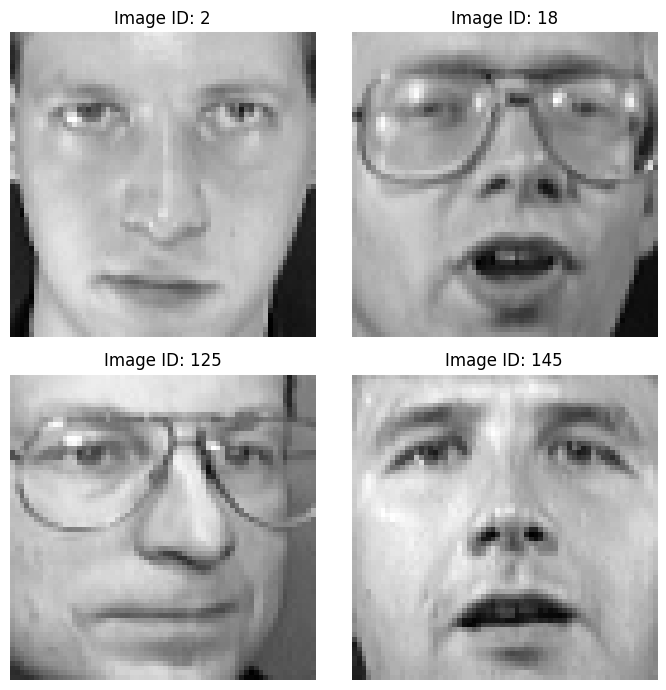

In [56]:
image_ids = [2, 18, 125, 145]

fig, axes = plt.subplots(2, 2, figsize=(7, 7))

for ax, image_id in zip(axes.flat, image_ids):
    ax.imshow(X[image_id].reshape(64, 64), cmap="gray")
    ax.set_title(f"Image ID: {image_id}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# Q2. Multiclass boosting from scratch

# (a) Before using the face data, create a three class example with at most 10 samples. Log one complete SAMME round: initial sample weights, weak learner predictions, weighted error, αt, and updated normalised weights.Your implementation on the face data must use the same update rule.

In [57]:
from sklearn.tree import DecisionTreeClassifier

X_small = np.array([
    [1, 1],
    [2, 1],
    [3, 2],
    [4, 3],
    [5, 4],
    [6, 5]
])

y_small = np.array([0, 0, 1, 1, 2, 2])

n = len(y_small)
K = len(np.unique(y_small))

weights = np.ones(n) / n

print("Initial sample weights:")
print(weights)

weak_tree = DecisionTreeClassifier(max_depth=1, random_state=42)
weak_tree.fit(X_small, y_small, sample_weight=weights)

predictions = weak_tree.predict(X_small)

print("\nTrue labels:")
print(y_small)

print("\nPredictions:")
print(predictions)

incorrect = predictions != y_small
error = np.sum(weights[incorrect])

print("\nWeighted error:", round(error, 4))

if error >= 1 - (1 / K):
    print("Weak learner is not better than random guessing.")
else:
    alpha = np.log((1 - error) / error) + np.log(K - 1)

    print("Learner weight (alpha):", round(alpha, 4))

    weights = weights * np.exp(alpha * incorrect)
    weights = weights / np.sum(weights)

    print("\nUpdated normalized sample weights:")
    print(np.round(weights, 4))
    print("Sum of updated weights:", round(np.sum(weights), 4))

Initial sample weights:
[0.16666667 0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]

True labels:
[0 0 1 1 2 2]

Predictions:
[0 0 1 1 1 1]

Weighted error: 0.3333
Learner weight (alpha): 1.3863

Updated normalized sample weights:
[0.0833 0.0833 0.0833 0.0833 0.3333 0.3333]
Sum of updated weights: 1.0


In [58]:
def train_samme(X_train, y_train, X_val, y_val, depth, rounds):
    n = len(y_train)
    K = len(np.unique(y_train))
    weights = np.ones(n) / n

    models = []
    alphas = []

    for t in range(rounds):
        tree = DecisionTreeClassifier(max_depth=depth, random_state=seed + t)
        tree.fit(X_train, y_train, sample_weight=weights)

        pred = tree.predict(X_train)
        error = np.sum(weights[pred != y_train])

       
        if error >= 1 - 1 / K:
            break

        if error <= 1e-12:
            models.append(tree)
            alphas.append(1.0)
            break

        alpha = np.log((1 - error) / error) + np.log(K - 1)

        weights *= np.exp(alpha * (pred != y_train))
        weights /= np.sum(weights)

        models.append(tree)
        alphas.append(alpha)

    return models, alphas

In [59]:
models, alphas = train_samme(
    X_train, y_train,
    X_val, y_val,
    depth=1,
    rounds=10
)

print("Number of boosting rounds completed:", len(models))
print("Learner weights (alphas):", np.round(alphas, 4))

Number of boosting rounds completed: 10
Learner weights (alphas): [0.7191 0.7465 0.7753 0.8058 0.8381 0.8723 0.9087 0.9474 0.9887 1.033 ]


**(b) On Olivetti Faces, use weak learner depths 1, 2, 3, 4 and 10, 25, 50, 100 rounds. Select depth and rounds using clean validation accuracy only. For the selected model, plot weighted training error, learner weight, maximum sample weight and the total weight carried by the 10 heaviest training images over rounds.**

In [113]:
def train_samme(X_train, y_train, depth, rounds):
    n = len(y_train)
    K = len(np.unique(y_train))
    weights = np.ones(n) / n
    models, alphas = [], []
    weight_history = []
    history = {"error": [], "alpha": [], "max_weight": [], "top10_weight": []}

    for t in range(rounds):
        tree = DecisionTreeClassifier(max_depth=depth, random_state=seed + t)
        tree.fit(X_train, y_train, sample_weight=weights)
        pred = tree.predict(X_train)
        error = np.sum(weights[pred != y_train])

        if error >= 1 - 1 / K:
            break

        if error <= 1e-12:
            models.append(tree)
            alphas.append(1.0)
            history["error"].append(error)
            history["alpha"].append(1.0)
            history["max_weight"].append(weights.max())
            history["top10_weight"].append(np.sort(weights)[-10:].sum())
            break

        alpha = np.log((1 - error) / error) + np.log(K - 1)
        history["error"].append(error)
        history["alpha"].append(alpha)

        weights *= np.exp(alpha * (pred != y_train))
        weights /= weights.sum()
        weight_history.append(weights.copy())

        history["max_weight"].append(weights.max())
        history["top10_weight"].append(np.sort(weights)[-10:].sum())

        models.append(tree)
        alphas.append(alpha)

    return models, alphas, history, weight_history



In [114]:
models, alphas, history, weight_history = train_samme(
    X_train, y_train, depth=4, rounds=50
)

In [115]:
depths = [1, 2, 3, 4]
round_counts = [10, 25, 50, 100]

results = []
best_val_acc = -1

for depth in depths:
    for rounds in round_counts:
        models, alphas, history,weight_history = train_samme(
            X_train, y_train, depth, rounds
        )

        scores = np.zeros((len(X_val), 40))

        for model, alpha in zip(models, alphas):
            pred = model.predict(X_val)
            scores[np.arange(len(X_val)), pred] += alpha

        val_pred = np.argmax(scores, axis=1)
        val_acc = accuracy_score(y_val, val_pred)

        results.append((depth, rounds, len(models), val_acc))

        print(
            f"Depth: {depth:<3} Rounds: {rounds:<4} "
            f"Completed: {len(models):<4} "
            f"Validation accuracy: {val_acc:.4f}"
        )

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_depth = depth
            best_rounds = rounds
            best_models = models
            best_alphas = alphas
            best_history = history

print("\nBest depth:", best_depth)
print("Best requested rounds:", best_rounds)
print("Actual rounds completed:", len(best_models))
print("Best validation accuracy:", round(best_val_acc, 4))

Depth: 1   Rounds: 10   Completed: 10   Validation accuracy: 0.0500
Depth: 1   Rounds: 25   Completed: 25   Validation accuracy: 0.0750
Depth: 1   Rounds: 50   Completed: 50   Validation accuracy: 0.1625
Depth: 1   Rounds: 100  Completed: 100  Validation accuracy: 0.1125
Depth: 2   Rounds: 10   Completed: 10   Validation accuracy: 0.0625
Depth: 2   Rounds: 25   Completed: 25   Validation accuracy: 0.0875
Depth: 2   Rounds: 50   Completed: 50   Validation accuracy: 0.2750
Depth: 2   Rounds: 100  Completed: 100  Validation accuracy: 0.2625
Depth: 3   Rounds: 10   Completed: 10   Validation accuracy: 0.1125
Depth: 3   Rounds: 25   Completed: 25   Validation accuracy: 0.2250
Depth: 3   Rounds: 50   Completed: 50   Validation accuracy: 0.2500
Depth: 3   Rounds: 100  Completed: 100  Validation accuracy: 0.3250
Depth: 4   Rounds: 10   Completed: 10   Validation accuracy: 0.1500
Depth: 4   Rounds: 25   Completed: 25   Validation accuracy: 0.3000
Depth: 4   Rounds: 50   Completed: 50   Validati

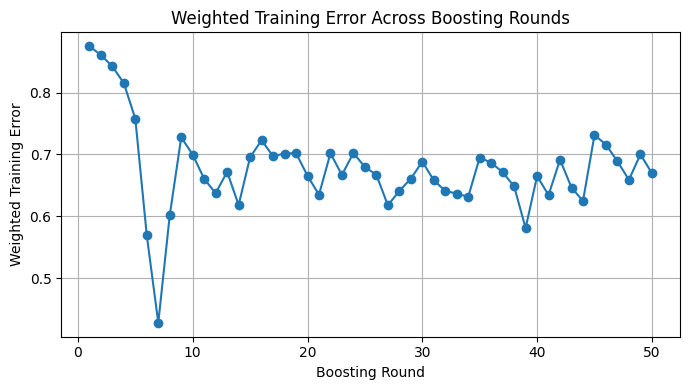

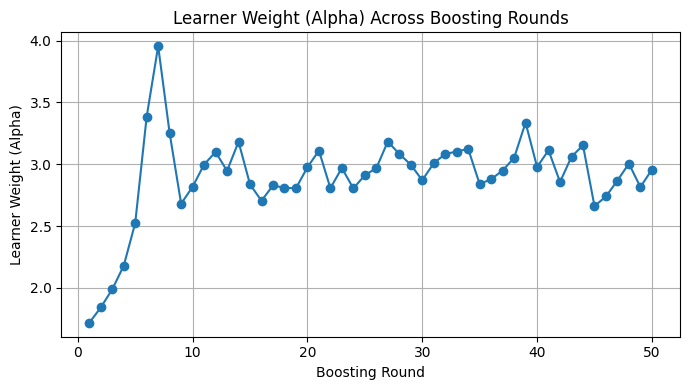

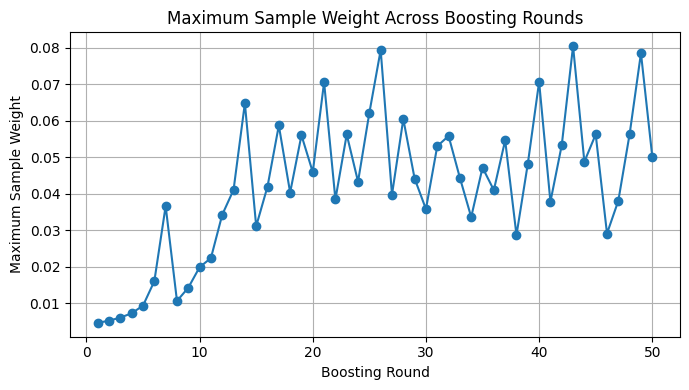

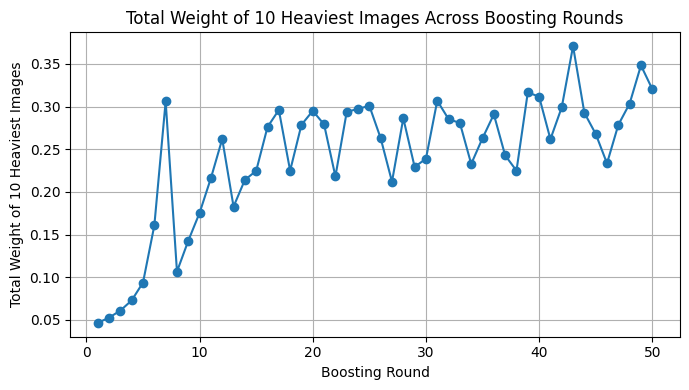

In [63]:
metrics = [
    ("error", "Weighted Training Error"),
    ("alpha", "Learner Weight (Alpha)"),
    ("max_weight", "Maximum Sample Weight"),
    ("top10_weight", "Total Weight of 10 Heaviest Images")
]

for key, title in metrics:
    plt.figure(figsize=(7, 4))
    plt.plot(
        range(1, len(best_history[key]) + 1),
        best_history[key],
        marker="o"
    )
    plt.xlabel("Boosting Round")
    plt.ylabel(title)
    plt.title(title + " Across Boosting Rounds")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

**(c) Compare boosting and bagging using 25, 50 and 100 learners. Report train, validation and clean test accuracy
and training time. Also inspect one training face that receives a very large boosting weight and use its prediction
history to explain why boosting repeatedly returns attention to that sample.**

In [116]:
import time
learner_counts = [25, 50, 100]

bag_models_by_B = {}
bag_training_times = {}

for B in learner_counts:
    start = time.time()
    models = []

    for i in range(B):
        rng_bag = np.random.default_rng(seed + i)
        ids = rng_bag.integers(
            0, len(X_train), size=len(X_train)
        )

        tree = DecisionTreeClassifier(
            max_depth=None,
            min_samples_leaf=1,
            random_state=seed + i
        )
        tree.fit(X_train[ids], y_train[ids])
        models.append(tree)

    bag_models_by_B[B] = models
    bag_training_times[B] = time.time() - start


boost_models_by_B = {}
boost_alphas_by_B = {}
boost_training_times = {}

for B in learner_counts:
    start = time.time()

    models, alphas, history, weights = train_samme(
        X_train, y_train, depth=4, rounds=B
    )

    boost_models_by_B[B] = models
    boost_alphas_by_B[B] = alphas
    boost_training_times[B] = time.time() - start

    print(
        f"Boosting requested: {B}, "
        f"learners completed: {len(models)}"
    )



def bag_predict(models, X_current):
    votes = np.array([
        model.predict(X_current) for model in models
    ])

    return np.array([
        np.bincount(votes[:, j], minlength=40).argmax()
        for j in range(len(X_current))
    ])


def boost_predict(models, alphas, X_current):
    scores = np.zeros((len(X_current), 40))

    for model, alpha in zip(models, alphas):
        pred = model.predict(X_current)
        scores[np.arange(len(X_current)), pred] += alpha

    return np.argmax(scores, axis=1)


print("ACCURACY COMPARISON")
print(
    f"{'Model':<12}{'Learners':<10}"
    f"{'Train Acc':<12}{'Val Acc':<12}"
    f"{'Clean Test':<12}{'Train Time(s)':<15}"
)

for B in learner_counts:

    
    models = bag_models_by_B[B]

    train_pred = bag_predict(models, X_train)
    val_pred = bag_predict(models, X_val)
    test_pred = bag_predict(models, X_test)

    print(
        f"{'Bagging':<12}{len(models):<10}"
        f"{accuracy_score(y_train, train_pred):<12.4f}"
        f"{accuracy_score(y_val, val_pred):<12.4f}"
        f"{accuracy_score(y_test, test_pred):<12.4f}"
        f"{bag_training_times[B]:<15.4f}"
    )

    
    models = boost_models_by_B[B]
    alphas = boost_alphas_by_B[B]

    train_pred = boost_predict(models, alphas, X_train)
    val_pred = boost_predict(models, alphas, X_val)
    test_pred = boost_predict(models, alphas, X_test)

    print(
        f"{'Boosting':<12}{len(models):<10}"
        f"{accuracy_score(y_train, train_pred):<12.4f}"
        f"{accuracy_score(y_val, val_pred):<12.4f}"
        f"{accuracy_score(y_test, test_pred):<12.4f}"
        f"{boost_training_times[B]:<15.4f}"
    )



models = boost_models_by_B[100]
alphas = boost_alphas_by_B[100]

models, alphas, boost_history, weight_history = train_samme(
    X_train, y_train, depth=4, rounds=100
)

if len(weight_history) > 0:
    final_weights = weight_history[-1]
    hard_index = np.argmax(final_weights)

    print("DIFFICULT TRAINING FACE")
    print("Training-set index:", hard_index)
    print("True identity:", y_train[hard_index])
    print("Initial weight:", round(1 / len(y_train), 6))
    print("Final weight:", round(final_weights[hard_index], 6))
    print(
        "Weight relative to initial:",
        round(final_weights[hard_index] * len(y_train), 2),
        "times"
    )

    prediction_history = np.array([
        model.predict(X_train[hard_index:hard_index + 1])[0]
        for model in models
    ])

    print("Predictions across rounds:")
    print(prediction_history.tolist())

    correct_rounds = np.where(
        prediction_history == y_train[hard_index]
    )[0] + 1

    print("Correctly predicted rounds:", correct_rounds.tolist())
    print("Correct rounds:", len(correct_rounds), "out of", len(models))
    print("Incorrect rounds:", len(models) - len(correct_rounds))
else:
    print("No boosting weight history was recorded.")


Boosting requested: 25, learners completed: 25
Boosting requested: 50, learners completed: 50
Boosting requested: 100, learners completed: 100
ACCURACY COMPARISON
Model       Learners  Train Acc   Val Acc     Clean Test  Train Time(s)  
Bagging     25        1.0000      0.8500      0.8375      50.1578        
Boosting    25        0.4625      0.3000      0.1625      14.1727        
Bagging     50        1.0000      0.8625      0.8375      99.9804        
Boosting    50        0.9375      0.4500      0.3500      28.3683        
Bagging     100       1.0000      0.8875      0.9000      196.6533       
Boosting    100       0.9875      0.4125      0.4000      56.6105        
DIFFICULT TRAINING FACE
Training-set index: 71
True identity: 11
Initial weight: 0.004167
Final weight: 0.067203
Weight relative to initial: 16.13 times
Predictions across rounds:
[0, 1, 11, 3, 4, 25, 27, 16, 2, 3, 13, 11, 4, 12, 20, 2, 10, 24, 1, 30, 11, 15, 22, 12, 2, 39, 3, 4, 11, 12, 20, 25, 2, 3, 26, 4, 11, 12, 2

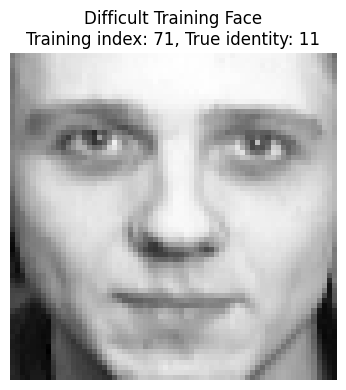

In [65]:
hard_index = 71

plt.figure(figsize=(4, 4))
plt.imshow(X_train[hard_index].reshape(64, 64), cmap="gray")
plt.title(
    f"Difficult Training Face\n"
    f"Training index: {hard_index}, "
    f"True identity: {y_train[hard_index]}"
)
plt.axis("off")
plt.tight_layout()
plt.show()



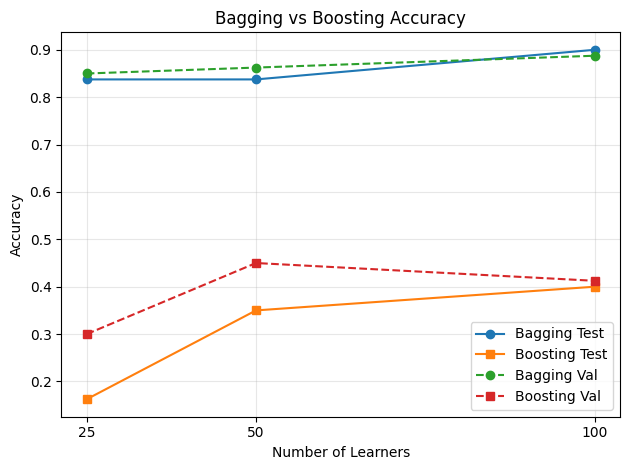

In [66]:
B = [25, 50, 100]

plt.plot(B, [0.8375, 0.8375, 0.9000], 'o-', label='Bagging Test')
plt.plot(B, [0.1625, 0.3500, 0.4000], 's-', label='Boosting Test')
plt.plot(B, [0.8500, 0.8625, 0.8875], 'o--', label='Bagging Val')
plt.plot(B, [0.3000, 0.4500, 0.4125], 's--', label='Boosting Val')

plt.xlabel('Number of Learners')
plt.ylabel('Accuracy')
plt.title('Bagging vs Boosting Accuracy')
plt.xticks(B)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

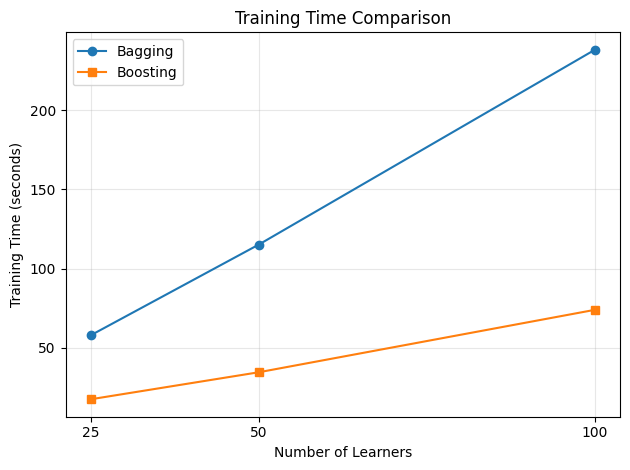

In [67]:
B = [25, 50, 100]
bag = [57.95, 115.20, 238.16]
boost = [17.52, 34.57, 73.97]

plt.plot(B, bag, 'o-', label='Bagging')
plt.plot(B, boost, 's-', label='Boosting')

plt.xlabel('Number of Learners')
plt.ylabel('Training Time (seconds)')
plt.title('Training Time Comparison')
plt.xticks(B)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

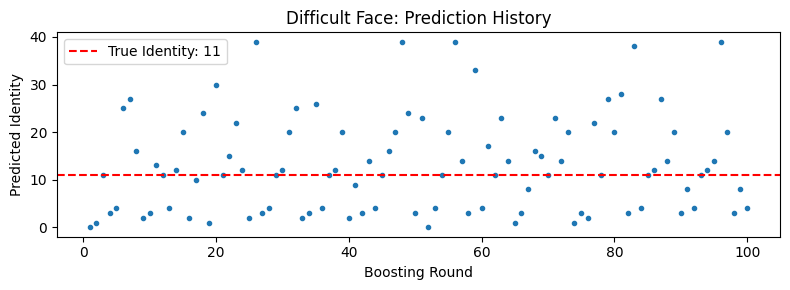

In [68]:
plt.figure(figsize=(8, 3))
plt.plot(range(1, len(prediction_history) + 1),
         prediction_history, 'o', markersize=3)
plt.axhline(11, color='red', linestyle='--', label='True Identity: 11')

plt.xlabel('Boosting Round')
plt.ylabel('Predicted Identity')
plt.title('Difficult Face: Prediction History')
plt.legend()
plt.tight_layout()
plt.show()

**(d) Freeze the selected boosting model. Evaluate the single tree baseline, final bagged model and boosting model on
the clean and masked test sets. Report accuracy and mean winning vote or probability for each. Find one face
for which bagging and boosting respond differently to the missing region and explain the difference using tree
disagreement and boosting sample weighting.**

In [118]:
single_tree = best["tree"]
bag_models = trees[:100]
boost_models = best_models
boost_weights = best_alphas

In [119]:
def tree_confidence(model, X):
    return model.predict_proba(X).max(axis=1).mean()

def bag_predict_confidence(models, X):
    votes = np.array([m.predict(X) for m in models])
    predictions = np.array([
        np.bincount(votes[:, i], minlength=40).argmax()
        for i in range(len(X))
    ])
    confidence = np.max(
        np.stack([
            np.bincount(votes[:, i], minlength=40) / len(models)
            for i in range(len(X))
        ]),
        axis=1
    ).mean()
    return predictions, confidence

def boost_predict_confidence(models, alphas, X):
    scores = np.zeros((len(X), 40))

    for model, alpha in zip(models, alphas):
        pred = model.predict(X)
        scores[np.arange(len(X)), pred] += alpha

    predictions = scores.argmax(axis=1)
    confidence = (
        scores.max(axis=1) / scores.sum(axis=1)
    ).mean()

    return predictions, confidence

print(f"{'Dataset':<10}{'Model':<15}{'Accuracy':<12}{'Confidence':<12}")

for dataset_name, X_current in [
    ("Clean", X_test),
    ("Masked", Xtest_mask)
]:
    
    pred = single_tree.predict(X_current)
    acc = accuracy_score(y_test, pred)
    conf = tree_confidence(single_tree, X_current)
    print(f"{dataset_name:<10}{'Single Tree':<15}{acc:<12.4f}{conf:<12.4f}")

   
    pred, conf = bag_predict_confidence(bag_models, X_current)
    acc = accuracy_score(y_test, pred)
    print(f"{dataset_name:<10}{'Bagging':<15}{acc:<12.4f}{conf:<12.4f}")

    
    pred, conf = boost_predict_confidence(
        boost_models, boost_weights, X_current
    )
    acc = accuracy_score(y_test, pred)
    print(f"{dataset_name:<10}{'Boosting':<15}{acc:<12.4f}{conf:<12.4f}")

Dataset   Model          Accuracy    Confidence  
Clean     Single Tree    0.4625      1.0000      
Clean     Bagging        0.9125      0.4029      
Clean     Boosting       0.3500      0.1275      
Masked    Single Tree    0.4625      1.0000      
Masked    Bagging        0.7250      0.3047      
Masked    Boosting       0.1750      0.1412      


In [120]:
print("Selected tree:", best["tree"])
print("Tree test accuracy:",
      accuracy_score(y_test, best["tree"].predict(X_test)))

Selected tree: DecisionTreeClassifier(random_state=26005)
Tree test accuracy: 0.4625


In [71]:
bag_clean, _ = bag_predict_confidence(bag_models, X_test)
bag_masked, _ = bag_predict_confidence(bag_models, Xtest_mask)

boost_clean, _ = boost_predict_confidence(
    boost_models, boost_weights, X_test
)
boost_masked, _ = boost_predict_confidence(
    boost_models, boost_weights, Xtest_mask
)
candidates = np.where(
    (bag_masked != boost_masked) &
    ((bag_clean != bag_masked) | (boost_clean != boost_masked))
)[0]

if len(candidates) > 0:
    i = candidates[0]
    print("Test-set index:", i)
    print("True identity:", y_test[i])
    print("Bagging: clean =", bag_clean[i], ", masked =", bag_masked[i])
    print("Boosting: clean =", boost_clean[i], ", masked =", boost_masked[i])



Test-set index: 0
True identity: 0
Bagging: clean = 0 , masked = 26
Boosting: clean = 2 , masked = 3


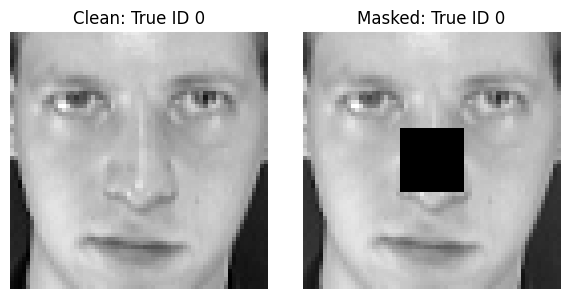

In [72]:
i = 0

fig, ax = plt.subplots(1, 2, figsize=(6, 3))

ax[0].imshow(X_test[i].reshape(64, 64), cmap="gray")
ax[0].set_title("Clean: True ID 0")

ax[1].imshow(Xtest_mask[i].reshape(64, 64), cmap="gray")
ax[1].set_title("Masked: True ID 0")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

In [91]:
boost_models = best_models
boost_weights = best_alphas

In [92]:
print("Boosting learners:", len(best_models))
print("Boosting weights:", len(best_alphas))
print("Selected depth: 4")
print("Selected rounds: 50")

Boosting learners: 50
Boosting weights: 50
Selected depth: 4
Selected rounds: 50


# Q3. Bias and variance as measured quantities

In [96]:
R = 30
B = 100
K = 40

class_indices = {
    c: np.where(y_train == c)[0]
    for c in range(K)
}

single_preds = []
bag_preds = []
boost_preds = []

single_acc = []
bag_acc = []
boost_acc = []

**(a) Report measured bias squared and variance for the selected single tree, bagging and boosting models. Also report
the mean and standard deviation of test accuracy across the 30 refits.**

In [97]:
start_all = time.time()

for r in range(R):
    rng_r = np.random.default_rng(seed + 1000 + r)
    sampled = np.concatenate([
        rng_r.choice(class_indices[c], size=6, replace=True)
        for c in range(K)
    ])
    X_boot = X_train[sampled]
    y_boot = y_train[sampled]


    single = DecisionTreeClassifier(
        max_depth=None,
        min_samples_leaf=1,
        random_state=seed
    )
    single.fit(X_boot, y_boot)
    p_single = single.predict(X_test)
    
    
    models = []

    for b in range(B):
        rng_b = np.random.default_rng(seed + r * 10000 + b)
        ids = rng_b.integers(0, len(X_boot), size=len(X_boot))

        model = DecisionTreeClassifier(
            max_depth=None,
            min_samples_leaf=1,
            random_state=seed + r * 10000 + b
        )
        model.fit(X_boot[ids], y_boot[ids])
        models.append(model)


    votes = np.array([m.predict(X_test) for m in models])
    p_bag = np.array([
        np.bincount(votes[:, j], minlength=K).argmax()
        for j in range(len(X_test))
    ])
    
    boost_models, boost_alphas, _, _ = train_samme(
        X_boot, y_boot, depth=4, rounds=50
    )
    
    scores = np.zeros((len(X_test), K))
    for model, alpha in zip(boost_models, boost_alphas):
        pred = model.predict(X_test)
        scores[np.arange(len(X_test)), pred] += alpha

    p_boost = scores.argmax(axis=1)
    
    single_preds.append(p_single)
    bag_preds.append(p_bag)
    boost_preds.append(p_boost)

    single_acc.append(accuracy_score(y_test, p_single))
    bag_acc.append(accuracy_score(y_test, p_bag))
    boost_acc.append(accuracy_score(y_test, p_boost))

    print(f"Completed repetition {r + 1}/{R}")

print(f"\nTotal time: {(time.time() - start_all) / 60:.2f} minutes")

def bias_variance(predictions, y_true, n_classes=40):
    predictions = np.asarray(predictions)
    n_runs, n_samples = predictions.shape
    one_hot = np.eye(n_classes)[predictions]
    mean_prediction = one_hot.mean(axis=0)
    true_one_hot = np.eye(n_classes)[y_true]

    bias2 = np.mean(np.sum(
        (mean_prediction - true_one_hot) ** 2, axis=1
    ))

    variance = np.mean(np.sum(
        (one_hot - mean_prediction) ** 2, axis=2
    ))

    return bias2, variance


print("BIAS-VARIANCE AND TEST ACCURACY")
print(f"{'Model':<12}{'Bias^2':<12}{'Variance':<12}"
      f"{'Mean Acc':<12}{'Std Acc':<12}")

for name, preds, accs in [
    ("Single Tree", single_preds, single_acc),
    ("Bagging", bag_preds, bag_acc),
    ("Boosting", boost_preds, boost_acc)
]:
    bias2, variance = bias_variance(preds, y_test, K)

    print(
        f"{name:<12}{bias2:<12.4f}{variance:<12.4f}"
        f"{np.mean(accs):<12.4f}{np.std(accs):<12.4f}"
    )



     

Completed repetition 1/30
Completed repetition 2/30
Completed repetition 3/30
Completed repetition 4/30
Completed repetition 5/30
Completed repetition 6/30
Completed repetition 7/30
Completed repetition 8/30
Completed repetition 9/30
Completed repetition 10/30
Completed repetition 11/30
Completed repetition 12/30
Completed repetition 13/30
Completed repetition 14/30
Completed repetition 15/30
Completed repetition 16/30
Completed repetition 17/30
Completed repetition 18/30
Completed repetition 19/30
Completed repetition 20/30
Completed repetition 21/30
Completed repetition 22/30
Completed repetition 23/30
Completed repetition 24/30
Completed repetition 25/30
Completed repetition 26/30
Completed repetition 27/30
Completed repetition 28/30
Completed repetition 29/30
Completed repetition 30/30

Total time: 103.74 minutes

Q3(a): BIAS-VARIANCE AND TEST ACCURACY
Model       Bias^2      Variance    Mean Acc    Std Acc     
Single Tree 0.4243      0.6674      0.4542      0.0502      
Bagging  

**(b) Repeat the calculation for single trees at one shallow depth, the selected depth and one much deeper depth. At
the same three depths build 100 tree bagged ensembles. Quantify how depth changes bias and variance, and how
much variance bagging removes at each depth.**

In [98]:
R = 30
B = 100
depths_q3 = [2, None, 16]

In [99]:
bootstrap_samples = []
for r in range(R):
    rng_r = np.random.default_rng(seed + 1000 + r)
    sampled = np.concatenate([
        rng_r.choice(np.where(y_train == c)[0], 6, replace=True)
        for c in range(40)
    ])
    bootstrap_samples.append(sampled)

In [100]:
def bias_variance(predictions, y_true, n_classes=40):
    predictions = np.asarray(predictions)
    one_hot = np.eye(n_classes)[predictions]
    mean_pred = one_hot.mean(axis=0)
    true_one_hot = np.eye(n_classes)[y_true]

    bias2 = np.mean(np.sum((mean_pred - true_one_hot) ** 2, axis=1))
    variance = np.mean(np.sum(
        (one_hot - mean_pred) ** 2, axis=2
    ))
    return bias2, variance
    
results_q3b = []

start_all = time.time()

for depth in depths_q3:
    single_predictions = []
    bag_predictions = []
    single_accuracies = []
    bag_accuracies = []
    
    for r, sampled in enumerate(bootstrap_samples):
        X_boot = X_train[sampled]
        y_boot = y_train[sampled]
        
        model = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=1,
            random_state=seed
        )
        model.fit(X_boot, y_boot)
        p_single = model.predict(X_test)
        
        votes = []
        
        for b in range(B):
            rng_b = np.random.default_rng(seed + r * 10000 + b)
            ids = rng_b.integers(0, len(X_boot), len(X_boot))

            tree_b = DecisionTreeClassifier(
                max_depth=depth,
                min_samples_leaf=1,
                random_state=seed + r * 10000 + b
            )
            
            tree_b.fit(X_boot[ids], y_boot[ids])
            votes.append(tree_b.predict(X_test))

        votes = np.asarray(votes)
        p_bag = np.array([
            np.bincount(votes[:, j], minlength=40).argmax()
            for j in range(len(X_test))
        ])
        
        single_predictions.append(p_single)
        bag_predictions.append(p_bag)
        single_accuracies.append(accuracy_score(y_test, p_single))
        bag_accuracies.append(accuracy_score(y_test, p_bag))

    for name, preds, accs in [
        ("Single Tree", single_predictions, single_accuracies),
        ("Bagging", bag_predictions, bag_accuracies)
    ]:
        bias2, variance = bias_variance(preds, y_test)
        results_q3b.append({
            "depth": str(depth),
            "model": name,
            "bias2": bias2,
            "variance": variance,
            "mean_acc": np.mean(accs),
            "std_acc": np.std(accs)
        })

print(f"Total time: {(time.time() - start_all) / 60:.2f} minutes")

print("DEPTH COMPARISON")
print(f"{'Depth':<10}{'Model':<14}{'Bias^2':<10}"
      f"{'Variance':<12}{'Mean Acc':<12}{'Std Acc':<10}")

for row in results_q3b:
    print(
        f"{row['depth']:<10}{row['model']:<14}"
        f"{row['bias2']:<10.4f}{row['variance']:<12.4f}"
        f"{row['mean_acc']:<12.4f}{row['std_acc']:<10.4f}"
    )


        


Total time: 168.36 minutes

Q3(b): DEPTH COMPARISON
Depth     Model         Bias^2    Variance    Mean Acc    Std Acc   
2         Single Tree   1.7997    0.0820      0.0592      0.0064    
2         Bagging       0.9398    0.8261      0.1171      0.0513    
None      Single Tree   0.4243    0.6674      0.4542      0.0502    
None      Bagging       0.1652    0.2748      0.7800      0.0320    
16        Single Tree   0.8940    0.5785      0.2637      0.0328    
16        Bagging       0.3460    0.4290      0.6125      0.0531    


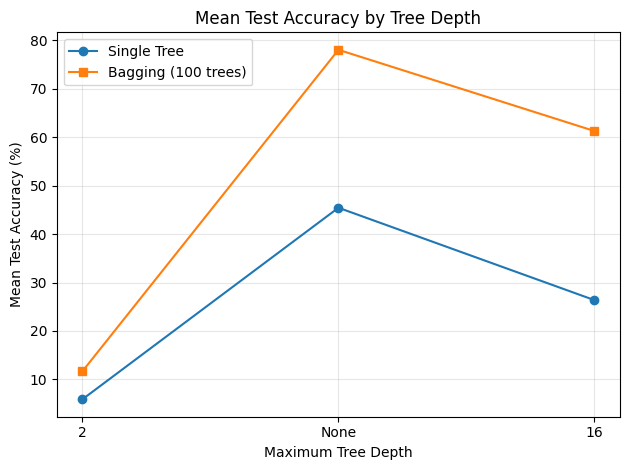

In [101]:
depths = ['2', 'None', '16']
single_tree = [5.92, 45.42, 26.37]
bagging = [11.71, 78.00, 61.25]

plt.plot(depths, single_tree, 'o-', label='Single Tree')
plt.plot(depths, bagging, 's-', label='Bagging (100 trees)')

plt.xlabel('Maximum Tree Depth')
plt.ylabel('Mean Test Accuracy (%)')
plt.title('Mean Test Accuracy by Tree Depth')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**(c) Determine whether the deepest tree is necessarily the depth at which bagging gives the largest improvement
in test accuracy. Your answer must use your measured bias, variance, leaf occupancy and disagreement results
rather than a generic statement about the bias variance tradeoff.**

In [102]:
results = {
    2: {
        "single": {"bias2": 1.7997, "variance": 0.0820, "accuracy": 5.92},
        "bagging": {"bias2": 0.9398, "variance": 0.8261, "accuracy": 11.71}
    },
    "None": {
        "single": {"bias2": 0.4243, "variance": 0.6674, "accuracy": 45.42},
        "bagging": {"bias2": 0.1652, "variance": 0.2748, "accuracy": 78.00}
    },
    16: {
        "single": {"bias2": 0.8940, "variance": 0.5785, "accuracy": 26.37},
        "bagging": {"bias2": 0.3460, "variance": 0.4290, "accuracy": 61.25}
    }
}

for depth, r in results.items():
    s, b = r["single"], r["bagging"]
    print(f"\nDepth: {depth}")
    print(f"Accuracy improvement: {b['accuracy'] - s['accuracy']:.2f} percentage points")
    print(f"Bias² reduction: {(s['bias2'] - b['bias2']):.4f}")
    print(f"Variance change: {(b['variance'] - s['variance']):+.4f}")


Depth: 2
Accuracy improvement: 5.79 percentage points
Bias² reduction: 0.8599
Variance change: +0.7441

Depth: None
Accuracy improvement: 32.58 percentage points
Bias² reduction: 0.2591
Variance change: -0.3926

Depth: 16
Accuracy improvement: 34.88 percentage points
Bias² reduction: 0.5480
Variance change: -0.1495


**End with one table for the selected single tree, bagging and boosting models containing clean test accuracy,
masked test accuracy, bias squared and variance. Using this table together with your earlier plots, explain which
model is most stable, which is most sensitive to the missing region, and whether the model with the lowest
variance is necessarily the model with the best test accuracy.**

In [109]:
import pandas as pd

final_table = pd.DataFrame({
    "Model": ["Single Tree", "Bagging (100 trees)", "SAMME Boosting (50 rounds)"],
    "Clean Test Accuracy (%)": [46.25, 91.25, 35.00],
    "Masked Test Accuracy (%)": [46.25, 72.50, 17.50],
    "Bias Squared": [0.4243, 0.1652, 0.7676],
    "Variance":    [0.6674, 0.2748, 0.7324]
})

print(final_table.to_string(index=False))

                     Model  Clean Test Accuracy (%)  Masked Test Accuracy (%)  Bias Squared  Variance
               Single Tree                    46.25                     46.25        0.4243    0.6674
       Bagging (100 trees)                    91.25                     72.50        0.1652    0.2748
SAMME Boosting (50 rounds)                    35.00                     17.50        0.7676    0.7324
